<a href="https://colab.research.google.com/github/ShahriarKamal2/Research-Practice/blob/experiment/experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    f1_score, roc_auc_score, precision_score, recall_score, roc_curve
)

df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(f"Initial dataset shape: {df.shape}")
df.head()

Initial dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df_clean = df.copy()

df_clean.drop(columns=["customerID"], inplace=True)

df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce")
print(f"Missing values in TotalCharges before imputation: {df_clean['TotalCharges'].isna().sum()}")
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0.0)

service_cols = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies"
]
for col in service_cols:
    df_clean[col] = df_clean[col].replace({"No internet service": "No"})

df_clean["MultipleLines"] = df_clean["MultipleLines"].replace({"No phone service": "No"})

df_clean["Churn"] = df_clean["Churn"].map({"No": 0, "Yes": 1})

print("Cleaned dataset info:")
print(df_clean["Churn"].value_counts(normalize=True).rename("Class Proportion"))

Missing values in TotalCharges before imputation: 11
Cleaned dataset info:
Churn
0    0.73463
1    0.26537
Name: Class Proportion, dtype: float64


In [3]:
df_clean["TenureCohort"] = pd.cut(
    df_clean["tenure"],
    bins=[-1, 12, 24, 48, 100],
    labels=["0-12m_New", "13-24m_Developing", "25-48m_Established", "49m+_Loyal"]
)
all_services = ["PhoneService", "MultipleLines"] + service_cols
df_clean["TotalServicesCount"] = (df_clean[all_services] == "Yes").sum(axis=1)

df_clean["ChargeDifference"] = df_clean["MonthlyCharges"] - (
    df_clean["TotalCharges"] / (df_clean["tenure"] + 1)
)

X = pd.get_dummies(df_clean.drop(columns=["Churn"]), drop_first=True)
y = df_clean["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "TotalServicesCount", "ChargeDifference"]
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print(f"Processed X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

Processed X_train shape: (5634, 28), X_test shape: (1409, 28)


In [4]:
log_reg = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)

y_pred_lr = log_reg.predict(X_test)
y_prob_lr = log_reg.predict_proba(X_test)[:, 1]

print("=== Logistic Regression Classification Report ===")
print(classification_report(y_test, y_pred_lr, digits=4))
print(f"Logistic Regression ROC-AUC: {roc_auc_score(y_test, y_prob_lr):.4f}")

=== Logistic Regression Classification Report ===
              precision    recall  f1-score   support

           0     0.9025    0.7246    0.8039      1035
           1     0.5069    0.7834    0.6155       374

    accuracy                         0.7402      1409
   macro avg     0.7047    0.7540    0.7097      1409
weighted avg     0.7975    0.7402    0.7539      1409

Logistic Regression ROC-AUC: 0.8461


In [5]:
rf_model = RandomForestClassifier(
    n_estimators=300, max_depth=8, min_samples_leaf=10,
    class_weight="balanced", random_state=42, n_jobs=-1
)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("=== Random Forest Classification Report ===")
print(classification_report(y_test, y_pred_rf, digits=4))
print(f"Random Forest ROC-AUC: {roc_auc_score(y_test, y_prob_rf):.4f}")

results_df = pd.DataFrame({
    "Model": ["Logistic Regression (Baseline)", "Random Forest (Tuned Depth)"],
    "Precision (Churn=1)": [precision_score(y_test, y_pred_lr), precision_score(y_test, y_pred_rf)],
    "Recall (Churn=1)": [recall_score(y_test, y_pred_lr), recall_score(y_test, y_pred_rf)],
    "F1-Score (Churn=1)": [f1_score(y_test, y_pred_lr), f1_score(y_test, y_pred_rf)],
    "ROC-AUC": [roc_auc_score(y_test, y_prob_lr), roc_auc_score(y_test, y_prob_rf)]
}).round(4)

display(results_df)

=== Random Forest Classification Report ===
              precision    recall  f1-score   support

           0     0.9003    0.7507    0.8188      1035
           1     0.5275    0.7701    0.6261       374

    accuracy                         0.7559      1409
   macro avg     0.7139    0.7604    0.7224      1409
weighted avg     0.8014    0.7559    0.7676      1409

Random Forest ROC-AUC: 0.8471


,Model,Precision (Churn=1),Recall (Churn=1),F1-Score (Churn=1),ROC-AUC
0,Logistic Regression (Baseline),0.5069,0.7834,0.6155,0.8461
1,Random Forest (Tuned Depth),0.5275,0.7701,0.6261,0.8471


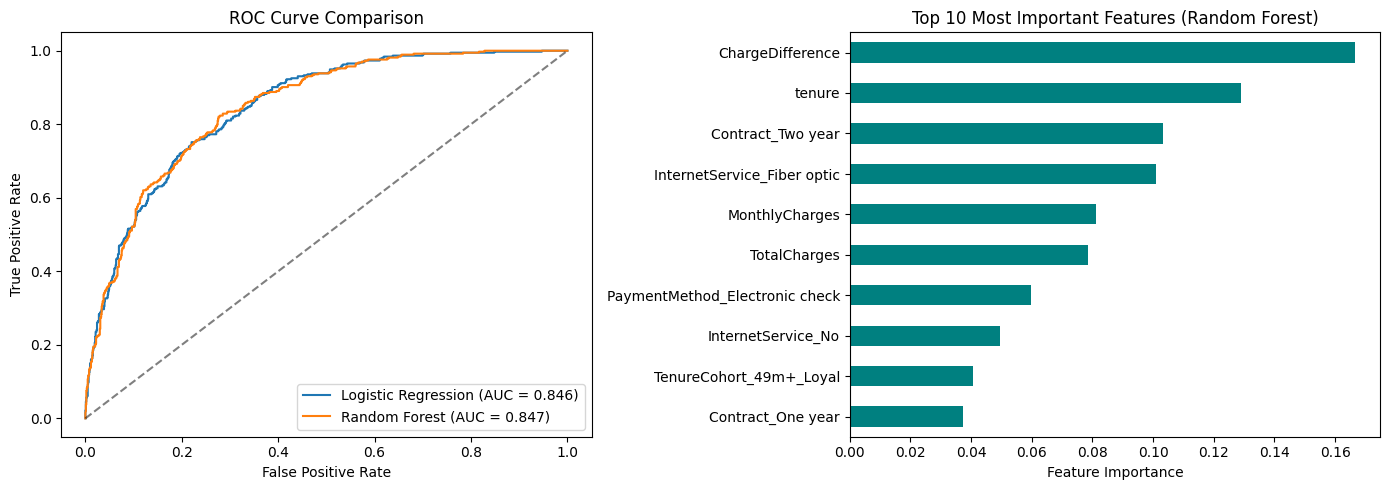

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
axes[0].plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_prob_lr):.3f})")
axes[0].plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {roc_auc_score(y_test, y_prob_rf):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set_title("ROC Curve Comparison")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()

# Plot 2: Random Forest Top 10 Features
importances = pd.Series(rf_model.feature_importances_, index=X_train.columns).nlargest(10)
importances.sort_values().plot(kind="barh", ax=axes[1], color="teal")
axes[1].set_title("Top 10 Most Important Features (Random Forest)")
axes[1].set_xlabel("Feature Importance")

plt.tight_layout()
plt.show()

### Final Findings & Future Improvements

Both Logistic Regression and Random Forest performed well on the test set (ROC-AUC ~0.85), catching nearly 80% of churning customers. Random Forest achieved a higher F1-score (0.63 vs. 0.62) and better precision by capturing non-linear patterns across contract types and our engineered billing features. Feature importance showed that month-to-month contracts, short tenure, high monthly bills, and electronic check payments are the biggest drivers of churn. Limiting tree depth (`max_depth=8`) and using balanced class weights were essential to prevent Random Forest from overfitting the majority class. With more time, I would test XGBoost or LightGBM and use `GridSearchCV` to tune hyperparameters automatically. I would also try SMOTE oversampling and adjust the decision threshold to better balance retention costs against lost revenue.